In [0]:
%restart_python

In [0]:
%pip install Sastrawi

Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
%pip install wordcloud

Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
# Library
import pandas as pd
import re
import string
import requests
from pyspark.sql.functions import col, trim
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

In [0]:
# API Key
SUPABASE_URL = "SUPABASE_URL"
SUPABASE_KEY = "UPABASE_KEY"

In [0]:
# Load Data
endpoint = f"{SUPABASE_URL}/rest/v1/news?select=*"

headers = {
    "apikey": SUPABASE_KEY,
    "Authorization": f"Bearer {SUPABASE_KEY}"
}

all_records = []
limit = 1000
offset = 0

while True:
    params = {
        "limit": limit,
        "offset": offset
    }

    resp = requests.get(
        endpoint,
        headers=headers,
        params=params
    )

    resp.raise_for_status()

    batch = resp.json()

    if not batch:
        break

    all_records.extend(batch)

    print(f"Retrieved: {len(all_records)} records")

    if len(batch) < limit:
        break

    offset += limit

# Convert all retrieved records to Pandas
pdf = pd.DataFrame(all_records)

# Convert Pandas to Spark DataFrame
df = spark.createDataFrame(pdf)

print("Total records retrieved:", len(all_records))
print("Total Pandas records:", len(pdf))
print("Total Spark records:", df.count())

Retrieved: 539 records
Total records retrieved: 539
Total Pandas records: 539
Total Spark records: 539


In [0]:
df.show(5)

+---+------+--------------------+--------------------+--------+--------------------+
| id|source|               title|                 url|category|           timestamp|
+---+------+--------------------+--------------------+--------+--------------------+
|907| detik|Tim SAR Temukan S...|https://news.deti...|    NULL|2025-12-28T04:38:...|
|910| detik|Presiden Iran: Ka...|https://news.deti...|    NULL|2025-12-28T04:38:...|
|923| detik|Jakarta Light Fes...|https://news.deti...|    NULL|2025-12-28T04:38:...|
|941|kompas|YouTuber Bongkar ...|https://tekno.kom...|    NULL|2025-12-28T04:39:...|
|942|kompas|Jadwal King Cup 2...|https://www.kompa...|    NULL|2025-12-28T04:39:...|
+---+------+--------------------+--------------------+--------+--------------------+
only showing top 5 rows


In [0]:
print("Total data sebelum pembersihan:", df.count())

df_clean = (
    df
    .dropna(subset=["title"])
    .filter(trim(col("title")) != "")
    .dropDuplicates(["title"])
    .select("title")
)

print("Total data setelah pembersihan:", df_clean.count())

df_clean.show(5)

Total data sebelum pembersihan: 539
Total data setelah pembersihan: 539
+--------------------+
|               title|
+--------------------+
|Tim SAR Temukan S...|
|Presiden Iran: Ka...|
|Jakarta Light Fes...|
|YouTuber Bongkar ...|
|Jadwal King Cup 2...|
+--------------------+
only showing top 5 rows


In [0]:
pdf = df_clean.toPandas()

In [0]:
def clean_text(text):
    text = str(text).lower()

    # hapus url
    text = re.sub(r'http\S+|www\S+', '', text)

    # hapus mention & hashtag
    text = re.sub(r'@\w+', '', text)
    text = re.sub(r'#', '', text)

    # hapus emoji
    text = re.sub(
        "[" 
        u"\U0001F600-\U0001F64F"
        u"\U0001F300-\U0001F5FF"
        u"\U0001F680-\U0001F6FF"
        u"\U0001F1E0-\U0001F1FF"
        u"\U00002700-\U000027BF"
        u"\U000024C2-\U0001F251"
        "]+",
        "",
        text
    )

    # hapus SEMUA selain huruf
    text = re.sub(r'[^a-z\s]', ' ', text)

    # rapikan spasi
    text = re.sub(r'\s+', ' ', text).strip()

    return text

In [0]:
def tokenize_text(text):
    return text.split()

In [0]:
normalization_dict = {
    "gk": "tidak", "ga": "tidak", "gak": "tidak", "nggak": "tidak",
    "ngga": "tidak", "tdk": "tidak", "tak": "tidak",
    "udh": "sudah", "udah": "sudah", "sdh": "sudah",
    "dr": "dari", "krn": "karena", "pdhl": "padahal",
    "yg": "yang", "dgn": "dengan", "dlm": "dalam",
    "aja": "saja", "bgt": "banget", "jg": "juga"
}

def normalize_tokens(tokens):
    return [normalization_dict.get(t, t) for t in tokens]

In [0]:
stopword_factory = StopWordRemoverFactory()
default_stopwords = set(stopword_factory.get_stop_words())

custom_stopwords = {
    "nih","sih","dong","deh","kan","lah","nya",
    "kok","loh","pun", "aja","banget","cuma","doang",
    "gitu","iya","ya","oh","eh","hehe","hmm","wkwk",
    "haha","udah","lagi","masih","dah","telah","baru",
    "akan","ingin","harus","boleh","bisa","sangat",
    "sekali","yang", "dan", "di", "ke", "dari","dalam", 
    "untuk","dengan", "ini","jadi", "saat", "hingga", 
    "tanpa","sudah"
}

negation_words = {"tidak","tak","gak","nggak","ngga","bukan","belum"}
stopwords = (default_stopwords | custom_stopwords) - negation_words
stopwords_wordcloud = (default_stopwords | custom_stopwords | negation_words)

def remove_stopwords(tokens):
    return [t for t in tokens if t not in stopwords]

stemmer = StemmerFactory().create_stemmer()

def stemming_tokens(tokens):
    return [stemmer.stem(t) for t in tokens]

In [0]:
def preprocess_text(text, stopwords):
    cleaned = clean_text(text)
    tokens = tokenize_text(cleaned)
    normalized = normalize_tokens(tokens)
    filtered = [t for t in normalized if t not in stopwords]
    stemmed = stemming_tokens(filtered)
    return stemmed

pdf["title_clean"] = pdf["title"].apply(
    lambda x: preprocess_text(x, stopwords)
)
pdf[["title", "title_clean"]].head()

,title,title_clean
0,Tim SAR Temukan Serpihan Kapal Tenggelam yang ...,"[tim, sar, temu, serpih, kapal, tenggelam, baw..."
1,Presiden Iran: Kami dalam Perang Total Lawan A...,"[presiden, iran, perang, total, lawan, as, isr..."
2,"Jakarta Light Festival Tak Sekadar Pesta, Ada ...","[jakarta, light, festival, tidak, sekadar, pes..."
3,"YouTuber Bongkar Isi HP Android Korea Utara, M...","[youtuber, bongkar, isi, hp, android, korea, u..."
4,Jadwal King Cup 2025 Hari Ini: Jonatan Christi...,"[jadwal, king, cup, hari, jonatan, christie, a..."


In [0]:
nrc_path = "/Volumes/workspace/drive/kamus-nrc/NRC-Emotion-Lexicon.csv"
nrc_df = pd.read_csv(nrc_path)

print("Kolom NRC:", nrc_df.columns)

Kolom NRC: Index(['English (en)', 'Afrikaans (af)', 'Albanian (sq)', 'Amharic (am)',
       'Arabic (ar)', 'Armenian (hy)', 'Azeerbaijani (az)', 'Basque (eu)',
       'Belarusian (be)', 'Bengali (bn)',
       ...
       'Positive', 'Negative', 'Anger', 'Anticipation', 'Disgust', 'Fear',
       'Joy', 'Sadness', 'Surprise', 'Trust'],
      dtype='object', length=115)


In [0]:
lexicon_dict = {}

for _, row in nrc_df.iterrows():
    score = {
        "positive": int(row.get("Positive", 0)),
        "negative": int(row.get("Negative", 0))
    }

    # Bahasa Indonesia
    id_word = row.get("Indonesian (id)")
    if isinstance(id_word, str):
        lexicon_dict[id_word.lower()] = score

    # Bahasa Inggris (jaga-jaga)
    en_word = row.get("English (en)")
    if isinstance(en_word, str):
        lexicon_dict[en_word.lower()] = score

print("Jumlah kata lexicon:", len(lexicon_dict))

Jumlah kata lexicon: 22940


In [0]:
def sentiment_score(tokens, lexicon):
    pos, neg = 0, 0

    if not isinstance(tokens, list):
        return pos, neg

    for t in tokens:
        if t in lexicon:
            pos += lexicon[t]["positive"]
            neg += lexicon[t]["negative"]

    return pos, neg

In [0]:
def sentiment_label(tokens, lexicon):
    pos, neg = sentiment_score(tokens, lexicon)

    if pos >= neg:
        return "Positif"
    else:
        return "Negatif"

In [0]:
pdf["sentiment"] = pdf["title_clean"].apply(
    lambda tokens: sentiment_label(tokens, lexicon_dict))
display(pdf[["title", "title_clean", "sentiment"]].head(5))

title,title_clean,sentiment
Tim SAR Temukan Serpihan Kapal Tenggelam yang Bawa Pelatih Valencia di Bajo,"List(tim, sar, temu, serpih, kapal, tenggelam, bawa, latih, valencia, bajo)",Positif
"Presiden Iran: Kami dalam Perang Total Lawan AS, Israel dan Eropa","List(presiden, iran, perang, total, lawan, as, israel, eropa)",Negatif
"Jakarta Light Festival Tak Sekadar Pesta, Ada Donasi untuk Bencana Sumatera","List(jakarta, light, festival, tidak, sekadar, pesta, donasi, bencana, sumatera)",Positif
"YouTuber Bongkar Isi HP Android Korea Utara, Menakutkan dan Bikin Kaget","List(youtuber, bongkar, isi, hp, android, korea, utara, takut, bikin, kaget)",Negatif
Jadwal King Cup 2025 Hari Ini: Jonatan Christie Beraksi di Perebutan Tempat Ketiga,"List(jadwal, king, cup, hari, jonatan, christie, aksi, rebut, tempat, tiga)",Positif


In [0]:
sentiment_counts = pdf["sentiment"].value_counts()
display(sentiment_counts)

sentiment
Positif    392
Negatif    147
Name: count, dtype: int64

In [0]:
pdf["text"] = pdf["title_clean"].apply(lambda x: " ".join(x))

pdf["label"] = pdf["sentiment"].map({
    "Negatif": 0,
    "Positif": 1
})

pdf[["text", "label"]].head()

,text,label
0,tim sar temu serpih kapal tenggelam bawa latih...,1
1,presiden iran perang total lawan as israel eropa,0
2,jakarta light festival tidak sekadar pesta don...,1
3,youtuber bongkar isi hp android korea utara ta...,0
4,jadwal king cup hari jonatan christie aksi reb...,1


In [0]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    pdf["text"],
    pdf["label"],
    test_size=0.2,
    random_state=42,
    stratify=pdf["label"]
)

print("Train:", len(X_train))
print("Test :", len(X_test))

Train: 431
Test : 108


In [0]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=3
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf  = tfidf.transform(X_test)

In [0]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC(
    class_weight="balanced",
    max_iter=5000
)

svm_model.fit(X_train_tfidf, y_train)

LinearSVC(class_weight='balanced', max_iter=5000)

In [0]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

y_pred = svm_model.predict(X_test_tfidf)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Negatif", "Positif"]
    )
)

Accuracy: 0.7407407407407407
F1 Score: 0.825
              precision    recall  f1-score   support

     Negatif       0.52      0.48      0.50        29
     Positif       0.81      0.84      0.82        79

    accuracy                           0.74       108
   macro avg       0.67      0.66      0.66       108
weighted avg       0.74      0.74      0.74       108



In [0]:
# Convert Spark DataFrame to Pandas
pdf = df.select("title").toPandas()

# Apply preprocessing
pdf["title_clean"] = pdf["title"].apply(preprocess_text)

# Check results
pdf[["title", "title_clean"]].head()

,title,title_clean
0,Tim SAR Temukan Serpihan Kapal Tenggelam yang ...,"[tim, sar, temu, serpih, kapal, tenggelam, baw..."
1,Presiden Iran: Kami dalam Perang Total Lawan A...,"[presiden, iran, perang, total, lawan, as, isr..."
2,"Jakarta Light Festival Tak Sekadar Pesta, Ada ...","[jakarta, light, festival, tidak, sekadar, pes..."
3,"YouTuber Bongkar Isi HP Android Korea Utara, M...","[youtuber, bongkar, isi, hp, android, korea, u..."
4,Jadwal King Cup 2025 Hari Ini: Jonatan Christi...,"[jadwal, king, cup, hari, jonatan, christie, a..."


In [0]:
pdf["title_wordcloud"] = pdf["title"].apply(
    lambda x: preprocess_text(x, stopwords_wordcloud)
)

pdf[["title", "title_wordcloud"]].head()

,title,title_wordcloud
0,Tim SAR Temukan Serpihan Kapal Tenggelam yang ...,"[tim, sar, temu, serpih, kapal, tenggelam, baw..."
1,Presiden Iran: Kami dalam Perang Total Lawan A...,"[presiden, iran, perang, total, lawan, as, isr..."
2,"Jakarta Light Festival Tak Sekadar Pesta, Ada ...","[jakarta, light, festival, sekadar, pesta, don..."
3,"YouTuber Bongkar Isi HP Android Korea Utara, M...","[youtuber, bongkar, isi, hp, android, korea, u..."
4,Jadwal King Cup 2025 Hari Ini: Jonatan Christi...,"[jadwal, king, cup, hari, jonatan, christie, a..."


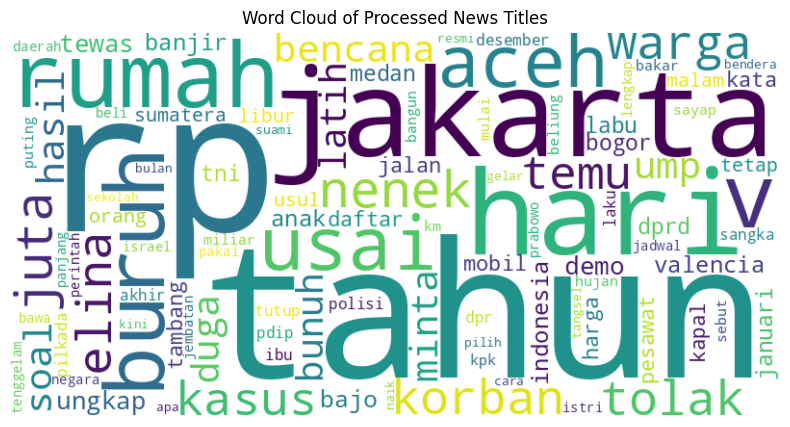

In [0]:

from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Combine all processed text
all_words = ' '.join(
    [' '.join(t) if isinstance(t, list) else str(t)
     for t in pdf['title_wordcloud'].dropna()]
)

# Generate Word Cloud
wordcloud = WordCloud(
    width=800,
    height=400,
    background_color='white',
    max_words=100,
    collocations=False
).generate(all_words)

# Display
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud of Processed News Titles')
plt.show()

In [0]:
from collections import Counter

# Menggabungkan seluruh token
all_tokens = [
    word
    for tokens in pdf["title_wordcloud"].dropna()
    for word in tokens
]

# Menghitung frekuensi kata
word_freq = Counter(all_tokens)

word_stats = pd.DataFrame(
    word_freq.items(),
    columns=["Kata", "Frekuensi"]
)

In [0]:
total_words = word_stats["Frekuensi"].sum()

word_stats["Proporsi"] = (
    word_stats["Frekuensi"] / total_words
)

word_stats["Persentase"] = (
    word_stats["Proporsi"] * 100
).round(2)

word_stats = word_stats.sort_values(
    by="Frekuensi",
    ascending=False
).reset_index(drop=True)

word_stats.head(5)

,Kata,Frekuensi,Proporsi,Persentase
0,rp,41,0.008579,0.86
1,tahun,37,0.007742,0.77
2,jakarta,35,0.007324,0.73
3,hari,32,0.006696,0.67
4,rumah,27,0.005650,0.56
